# 00c — Rafael: Fila de Unidades Suspeitas (Dados Brutos)
Objetivo: listar 20 UCs com maior queda de consumo (média 2026-01 a 2026-06 vs 2025-01 a 2025-06) e estatísticas de inspeções.

In [1]:
import sys
from pathlib import Path

# Resolução de caminho compatível com script .py e notebook .ipynb (sem __file__ em notebooks)
_starts = [Path.cwd()]
if "__file__" in globals():
    _starts.append(Path(__file__).resolve().parent)

def _find_project_root(starts):
    checked = []
    for item in starts:
        current = item.resolve()
        if current.is_file():
            current = current.parent
        for candidate in (current, *current.parents):
            if candidate in checked:
                continue
            checked.append(candidate)
            if (candidate / "data").is_dir() and (candidate / "analisys").is_dir():
                return candidate
    locations = ", ".join(str(s.resolve()) for s in starts)
    raise FileNotFoundError(
        f"Raiz do projeto não encontrada. Esperado 'data/' e 'analisys/' a partir de: {locations}"
    )

PROJECT_ROOT = _find_project_root(_starts)
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import json
import matplotlib
# Backend inline para exibir gráficos no notebook
import matplotlib_inline.backend_inline
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

# Configuração para saída de alta qualidade no notebook
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

# Carregamento dos dados brutos (funções inline, sem _helpers)

In [2]:
_REQUIRED_DATA_FILES = (
    "unidades_consumidoras.csv",
    "medidores.csv",
    "faturas.csv",
    "geracao_distribuida.csv",
    "ocorrencias_rede.csv",
    "atendimentos.json",
    "inspecoes.xlsx",
)

def _read_csv(path: Path, **kwargs) -> pd.DataFrame:
    sample = path.read_text(encoding="utf-8", errors="replace").splitlines()[:1]
    if not sample:
        raise ValueError(f"Arquivo CSV vazio: {path}")
    separator = ";" if sample[0].count(";") > sample[0].count(",") else ","
    options = {"sep": separator, **kwargs}
    try:
        return pd.read_csv(path, **options)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", **options)

def _read_file(path: Path, **kwargs) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return _read_csv(path, **kwargs)
    if suffix == ".json":
        return pd.read_json(path, **kwargs)
    if suffix == ".xlsx":
        return pd.read_excel(path, **kwargs)
    raise ValueError(f"Formato não suportado: {path}")

def resolve_data_file(name: str, root: Path) -> Path:
    data_dir = root / "data"
    direct = data_dir / name
    if direct.is_file():
        return direct
    matches = sorted(p for p in data_dir.rglob(Path(name).name) if p.is_file())
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(f"Arquivo obrigatório '{name}' não encontrado em {data_dir} nem subdiretórios.")
    raise FileNotFoundError(f"Arquivo '{name}' encontrado em múltiplos locais: {', '.join(str(p) for p in matches)}")

def resolve_readings_files(root: Path) -> list[Path]:
    data_dir = root / "data"
    candidates = sorted(p for p in data_dir.rglob("*.csv") if p.is_file() and "leitura" in p.stem.lower())
    if not candidates:
        raise FileNotFoundError(f"Nenhum CSV de leituras encontrado em {data_dir} ou subdiretórios.")
    return candidates

def load_all_raw_data(root: Path) -> dict[str, pd.DataFrame]:
    files = {name.removesuffix(Path(name).suffix): resolve_data_file(name, root) for name in _REQUIRED_DATA_FILES}
    files["leituras"] = resolve_readings_files(root)
    return {
        "uc": _read_file(files["unidades_consumidoras"]),
        "faturas": _read_file(files["faturas"]),
        "leituras": pd.concat([_read_file(p) for p in files["leituras"]], ignore_index=True, sort=False),
        "medidores": _read_file(files["medidores"]),
        "gd": _read_file(files["geracao_distribuida"]),
        "ocorrencias": _read_file(files["ocorrencias_rede"]),
        "atendimentos": _read_file(files["atendimentos"]),
        "inspecoes": _read_file(files["inspecoes"]),
    }

def to_numeric_safe(series: pd.Series, decimal_comma: bool = False) -> tuple[pd.Series, int]:
    values = series.astype("string").str.strip()
    if decimal_comma:
        values = values.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    converted = pd.to_numeric(values, errors="coerce")
    failures = int((values.notna() & values.ne("") & converted.isna()).sum())
    return converted, failures

def safe_divide(numerator: float, denominator: float):
    if denominator is None or pd.isna(denominator) or denominator == 0:
        return None
    return float(numerator / denominator)

def pct_change_safe(current: float | None, previous: float | None) -> float | None:
    # queda = (media_2025 - media_2026) / media_2025 * 100 (positivo = queda)
    if previous is None or pd.isna(previous) or previous == 0 or current is None or pd.isna(current):
        return None
    return float((previous - current) / previous * 100)

def get_resultados_dir(subdir: str, root: Path) -> Path:
    directory = root / "analisys" / "resultados" / subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

def get_graficos_dir(subdir: str | None, root: Path) -> Path:
    directory = root / "analisys" / "graficos"
    if subdir:
        directory /= subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

# Carrega dados
dfs = load_all_raw_data(PROJECT_ROOT)

# Diretórios de saída
PASTA_RESULTADOS = get_resultados_dir("analise_negocio/dados_brutos", PROJECT_ROOT)
PASTA_GRAFICOS = get_graficos_dir("analise_negocio", PROJECT_ROOT)

def exibir_grafico(fig, nome: str):
    output = PASTA_GRAFICOS / f"{nome}.png"
    fig.savefig(output, dpi=150, bbox_inches="tight")
    print(f"Gráfico gerado: {output}")
    plt.show(fig)  # Exibe no notebook
    plt.close(fig)  # Libera memória

C:\Users\julio\AppData\Local\Temp\ipykernel_9356\1688723324.py:18: DtypeWarning: Columns (4,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)
C:\Users\julio\AppData\Local\Temp\ipykernel_9356\1688723324.py:18: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)


In [3]:
uc = dfs["uc"]
leit = dfs["leituras"]
ins = dfs["inspecoes"]

# Conversão consumo
print("=== Exemplo conversão consumo_kwh (5 primeiras linhas) ===")
print(leit[["id_leitura", "consumo_kwh"]].head(5).to_string(index=False))
leit["consumo_num"], falhas_consumo = to_numeric_safe(leit["consumo_kwh"], decimal_comma=True)
print("\nConvertidos:")
print(leit[["id_leitura", "consumo_kwh", "consumo_num"]].head(5).to_string(index=False))
leit["mes_ref_dt"] = pd.to_datetime(leit["mes_referencia"], format="%Y-%m", errors="coerce")
print(f"\nFalhas conversão consumo_kwh: {falhas_consumo}")

=== Exemplo conversão consumo_kwh (5 primeiras linhas) ===
 id_leitura  consumo_kwh
LT000000000        145.0
LT000000001        163.0
LT000000002        184.0
LT000000003        237.0
LT000000004        331.0

Convertidos:
 id_leitura  consumo_kwh  consumo_num
LT000000000        145.0         1450
LT000000001        163.0         1630
LT000000002        184.0         1840
LT000000003        237.0         2370
LT000000004        331.0         3310

Falhas conversão consumo_kwh: 0


In [4]:
# Períodos
p2025 = leit[(leit["mes_referencia"] >= "2025-01") & (leit["mes_referencia"] <= "2025-06")]
p2026 = leit[(leit["mes_referencia"] >= "2026-01") & (leit["mes_referencia"] <= "2026-06")]

media_2025 = p2025.groupby("id_uc")["consumo_num"].mean()
media_2026 = p2026.groupby("id_uc")["consumo_num"].mean()

# Queda percentual: queda = (media_2025 - media_2026) / media_2025 * 100 (positivo = queda)
df = pd.DataFrame({"media_2025": media_2025, "media_2026": media_2026}).dropna()
df["queda_pct"] = df.apply(lambda r: pct_change_safe(r["media_2026"], r["media_2025"]), axis=1)
df["energia_recuperar_kwh"] = (df["media_2025"] - df["media_2026"]) * 6

# Verifica se energia_recuperar_kwh é positiva nas 20 UCs
# Top 20 maior queda (maior queda_pct)
top20 = df.nlargest(20, "queda_pct")

print("Top 20 quedas:")
print(top20[["queda_pct", "energia_recuperar_kwh"]].to_string())

# Verifica energia_recuperar_kwh positiva
negativas = top20[top20["energia_recuperar_kwh"] <= 0]
if len(negativas) > 0:
    print(f"\nATENCAO: {len(negativas)} UCs com energia_recuperar_kwh <= 0:")
    print(negativas[["energia_recuperar_kwh"]].to_string())
else:
    print("\nOK: Todas as 20 UCs tem energia_recuperar_kwh positiva.")

Top 20 quedas:
             queda_pct  energia_recuperar_kwh
id_uc                                        
UC144979  45794.708995         1483748.571429
UC113791  35878.407557          759597.142857
UC126245  30599.337748               924100.0
UC117479  29351.902923         1520428.571429
UC144301  25758.236025         1481098.571429
UC128007  24536.163522               780250.0
UC106328  24092.941176         1579808.571429
UC108734  23324.210526               886320.0
UC107185  22472.185430               678660.0
UC127042  21416.483516               779560.0
UC109306  21404.225352               911820.0
UC107983  21374.115044               966110.0
UC122223  21200.000000               816200.0
UC134718  21148.522167               858630.0
UC117519  20927.750000               837110.0
UC131168  20662.557078               905020.0
UC125214  20656.589147               799410.0
UC101425  20478.427613         1220514.285714
UC129710  20412.857143               857340.0
UC138010  19954.587

In [5]:
# Para cada UC do top 20, reporte quantas leituras negativas tem em 2026-01 a 2026-06
# e se a média de 2026 muda sem elas (só informação, sem remover nada)
leit_neg_2026 = leit[(leit["mes_referencia"] >= "2026-01") & (leit["mes_referencia"] <= "2026-06") & (leit["consumo_num"] < 0)]
leit_neg_2026_por_uc = leit_neg_2026.groupby("id_uc").size()

top20_info = []
for uc_id in top20.index:
    media_2026_com = media_2026.get(uc_id)
    n_neg = int(leit_neg_2026_por_uc.get(uc_id, 0))

    # Média sem leituras negativas
    leit_uc_2026 = p2026[p2026["id_uc"] == uc_id]
    leit_uc_2026_pos = leit_uc_2026[leit_uc_2026["consumo_num"] >= 0]
    media_2026_sem_neg = leit_uc_2026_pos["consumo_num"].mean() if not leit_uc_2026_pos.empty else np.nan

    top20_info.append({
        "id_uc": uc_id,
        "queda_pct": float(top20.loc[uc_id, "queda_pct"]),
        "energia_recuperar_kwh": float(top20.loc[uc_id, "energia_recuperar_kwh"]),
        "motivo": f"queda de {top20.loc[uc_id, 'queda_pct']:.2f}%",
        "leituras_negativas_2026": n_neg,
        "media_2026_com_todas": float(media_2026_com) if pd.notna(media_2026_com) else "sem dado",
        "media_2026_sem_negativas": float(media_2026_sem_neg) if pd.notna(media_2026_sem_neg) else "sem dado",
        "media_muda_sem_negativas": "sim" if pd.notna(media_2026_com) and pd.notna(media_2026_sem_neg) and abs(media_2026_com - media_2026_sem_neg) > 0.01 else "não",
    })

In [6]:
# Inspeções
ins_count = len(ins)
resultado_counts = ins["resultado"].value_counts(dropna=False).to_dict()
ins["kwh_recuperado_num"] = pd.to_numeric(ins["kwh_recuperado"].astype(str).str.replace(",", "."), errors="coerce")
falhas_kwh = int(ins["kwh_recuperado_num"].isna().sum())
total_kwh_rec = float(ins["kwh_recuperado_num"].sum())
print(f"Total inspeções: {ins_count}")
print(f"Contagem por resultado: {resultado_counts}")
print(f"Total kwh_recuperado: {total_kwh_rec}")
print(f"Falhas conversão kwh_recuperado: {falhas_kwh}")

Total inspeções: 511
Contagem por resultado: {'IRREGULARIDADE CONFIRMADA': 279, 'SEM IRREGULARIDADE': 175, 'Irregularidade Confirmada': 16, 'irregularidade confirmada': 12, 'CONFIRMADA': 11, 'sem irregularidade': 10, 'NADA CONSTA': 6, 'Sem Irregularidade': 2}
Total kwh_recuperado: 519964.0
Falhas conversão kwh_recuperado: 0


Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\01_top20_energia_recuperar.png


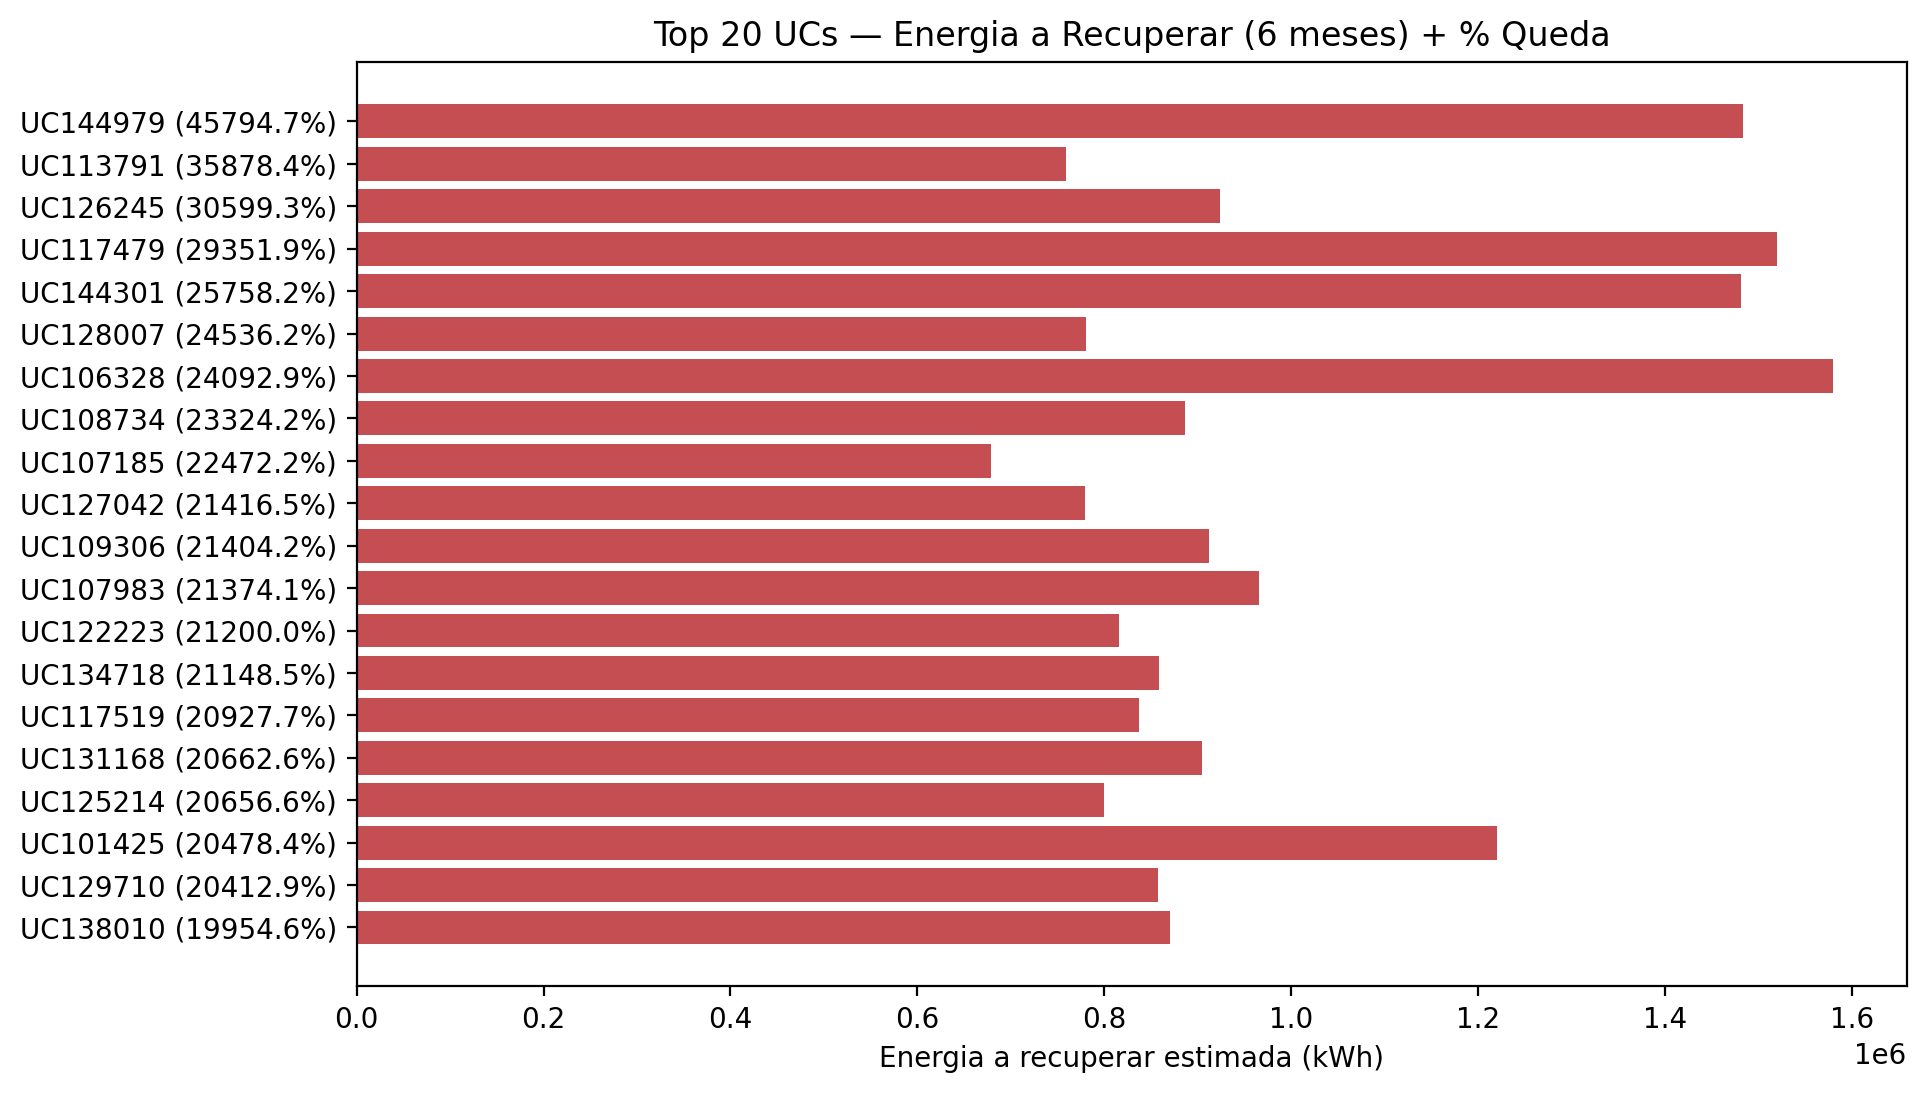

In [7]:
# Gráfico 1: barras das 20 UCs com energia estimada
fig, ax = plt.subplots(figsize=(10, 6))
ucs_labels = [f"{i['id_uc']} ({i['queda_pct']:.1f}%)" for i in top20_info]
energias = [i['energia_recuperar_kwh'] for i in top20_info]
ax.barh(ucs_labels[::-1], energias[::-1], color="#c44e52")
ax.set_xlabel("Energia a recuperar estimada (kWh)")
ax.set_title("Top 20 UCs — Energia a Recuperar (6 meses) + % Queda")
exibir_grafico(fig, "01_top20_energia_recuperar")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\02_inspecoes_por_resultado.png


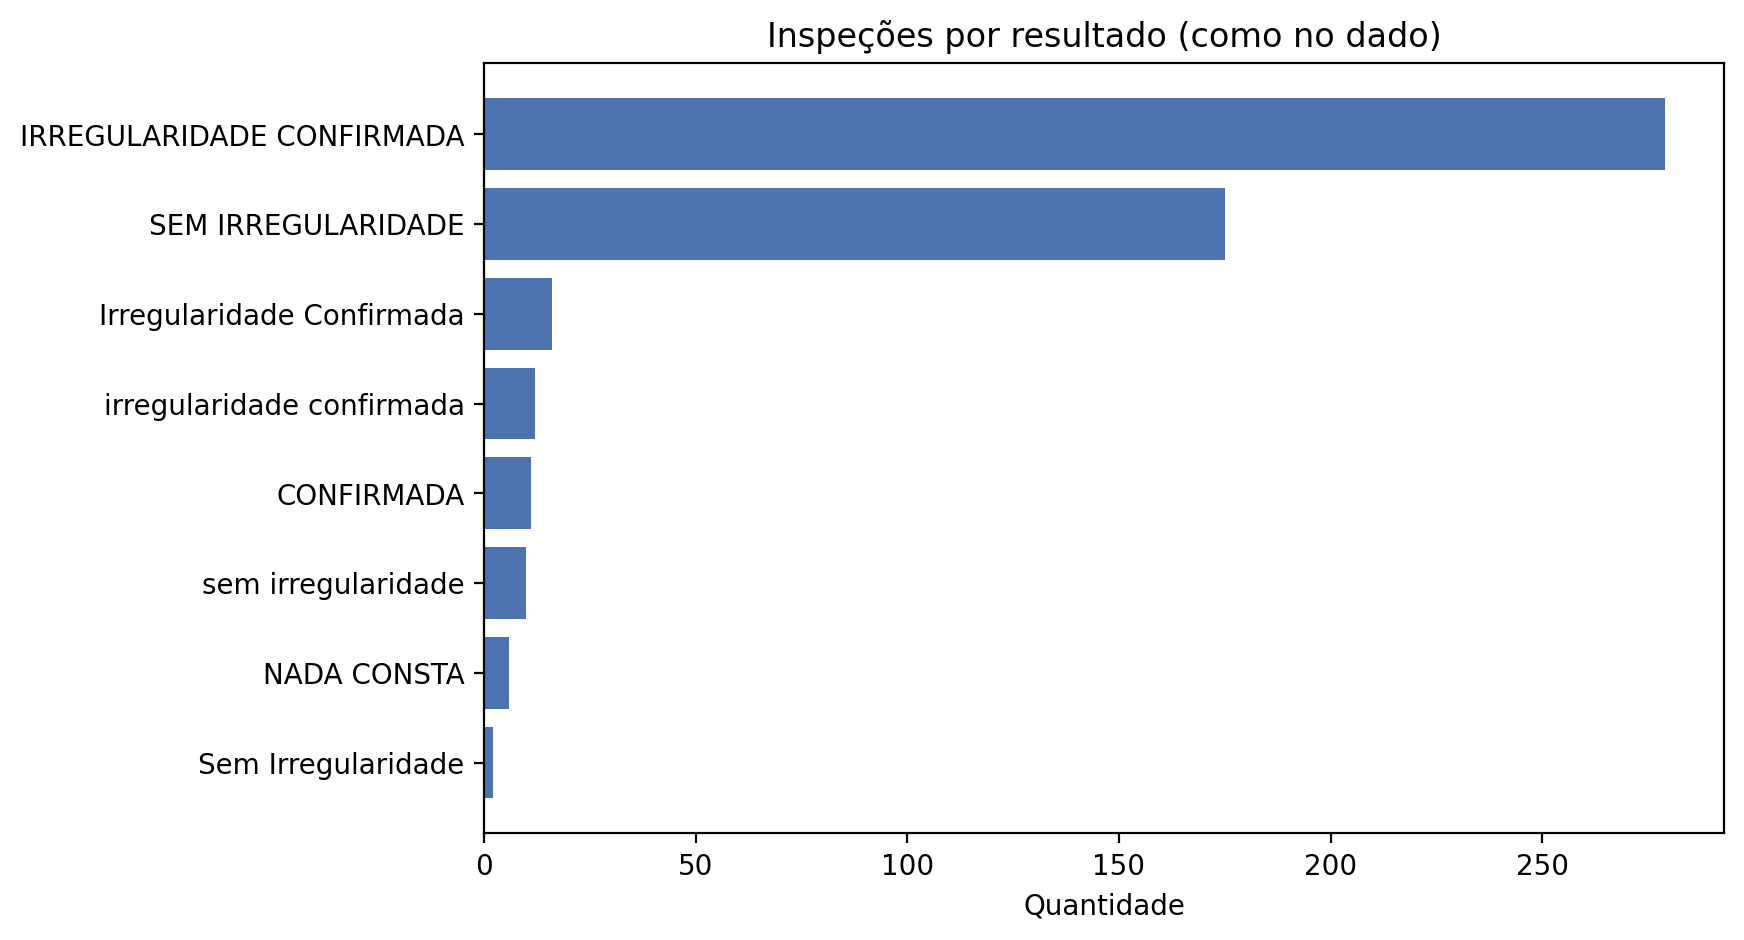

In [8]:
# Gráfico 2: inspeções por resultado
fig, ax = plt.subplots(figsize=(8, 5))
res = pd.Series(resultado_counts).sort_values()
ax.barh(res.index.astype(str), res.values, color="#4c72b0")
ax.set_xlabel("Quantidade")
ax.set_title("Inspeções por resultado (como no dado)")
exibir_grafico(fig, "02_inspecoes_por_resultado")

In [9]:
# Helper para JSON seguro
def json_safe(obj):
    if isinstance(obj, dict):
        return {k: json_safe(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [json_safe(v) for v in obj]
    elif isinstance(obj, float):
        if pd.isna(obj) or np.isinf(obj):
            return None
        return obj
    elif pd.isna(obj):
        return None
    return obj

def fmt_valor(v):
    if v is None or pd.isna(v) or (isinstance(v, float) and np.isinf(v)):
        return "indefinido"
    return v

In [10]:
resultado_json = {
    "regra_queda": "queda = (média 2025-01 a 2025-06 - média 2026-01 a 2026-06) / média 2025 * 100 (positivo = queda)",
    "energia_recuperar_formula": "(média 2025 - média 2026) * 6 meses",
    "top20_ucs": {
        i["id_uc"]: {
            "queda_pct": fmt_valor(i["queda_pct"]),
            "energia_recuperar_kwh": fmt_valor(i["energia_recuperar_kwh"]),
            "motivo": i["motivo"],
            "leituras_negativas_2026": i["leituras_negativas_2026"],
            "media_2026_com_todas": fmt_valor(i["media_2026_com_todas"]),
            "media_2026_sem_negativas": fmt_valor(i["media_2026_sem_negativas"]),
            "media_muda_sem_negativas": i["media_muda_sem_negativas"],
        }
        for i in top20_info
    },
    "inspecoes": {
        "total": int(ins_count),
        "por_resultado": {str(k): int(v) for k, v in resultado_counts.items()},
        "total_kwh_recuperado": fmt_valor(total_kwh_rec),
        "falhas_conversao_kwh_recuperado": falhas_kwh,
    },
    "verificacoes": {
        "todas_energia_recuperar_positiva": len(negativas) == 0,
        "ucs_com_energia_nao_positiva": len(negativas),
    },
    "observacoes": [
        f"Falhas conversão consumo_kwh: {falhas_consumo}",
        "Apenas UCs com leituras em ambos os períodos foram consideradas.",
        "Queda calculada como (média_2025 - média_2026) / média_2025 * 100 (positivo = queda).",
        "Para cada UC do top 20: reportadas leituras negativas em 2026 e média sem elas (informação apenas, nada removido).",
        "Energia a recuperar = (média_2025 - média_2026) * 6 meses.",
    ],
}

resultado_json = json_safe(resultado_json)

with open(PASTA_RESULTADOS / "rafael_fila_de_unidades_suspeitas_dados_brutos.json", "w", encoding="utf-8") as f:
    json.dump(resultado_json, f, ensure_ascii=False, indent=2, allow_nan=False)
print("JSON salvo.")

JSON salvo.
